# vcfrop — value-directed free recall, full analysis

Subjects study 15-word lists in which each word carries a point value (a "tip"). They
free-recall the list, give a value estimate for **each item as they recall it**, and give
**one** estimate for the list as a whole. Lists come in two kinds: the values are either
**random** across serial positions (`pres_types == 1`) or **temporally autocorrelated**
(`pres_types == 2`).

Two questions run through this notebook:

1. **Is the list estimate built from the items they recalled, the items they didn't, or
   both?** A pure recalled-items account puts the non-recalled coefficient at zero.
2. **Where in the list, and where in the recall sequence, is estimation least accurate?**
   That is what sections 10's curves are for — they are the estimation-error analogs of the
   SPC, lag-CRP and PFR.

The notebook only orchestrates: every number is computed by `vcfrop/`, the same code the
test suite covers, so nothing here can drift from what is tested.

**Sample.** 10 subjects, 470 lists, built directly from the raw BIDS event log in
`vcfrop_modified_data/` — the hand-curated version, with `modifiedtrials.xlsx` logging what
was corrected and why. Session 0 (a shorter practice session) is excluded, which also drops
LTP663, who has no other session.

The analyses in sections 8 and 9 were ported from the sibling `vcbeh` project, which ran them
on 22–26 subjects and 1080–1120 lists. The analyses carry over; the statistical power does
not. Nothing here should be read as an established effect.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vcfrop import (ana_vavi_e2frop, linreg as L, load_data, load_raw, load_res,
                    plots, rawio, valuecurves)
from vcfrop.plots import RAND, RAND_LABEL, TEMP, TEMP_LABEL, publication_style
from vcfrop.regression import run_regression
from vcfrop.stats import format_report, run_stats

RAW_DIR = ROOT.parent.parent / "vcfrop_modified_data"
DATA_FILE = ROOT / "data_083026_xs0.mat"
REFERENCE_FILE = ROOT / "res_083026_xs0.mat"

pd.set_option("display.precision", 4)
warnings.filterwarnings("ignore", category=RuntimeWarning)

print(f"raw log:   {RAW_DIR}")
print(f"data:      {DATA_FILE.name}")
print(f"reference: {REFERENCE_FILE.name}")

raw log:   /Users/zrentala/Documents/Value Courier/vcfrop_modified_data
data:      data_083026_xs0.mat
reference: res_083026_xs0.mat


## 1. The dataset

In [2]:
data = load_raw(RAW_DIR)          # hand-curated event log, session 0 excluded
ll = data.list_length

pd.DataFrame(
    [
        ("trials", data.subject.shape[0]),
        ("subjects", len(np.unique(data.subject))),
        ("sessions", len(np.unique(data.session))),
        ("list length", ll),
        ("recall slots", data.recalls.shape[1]),
        ("random-value lists", int((data.pres_types == 1).sum())),
        ("autocorrelated-value lists", int((data.pres_types == 2).sum())),
    ],
    columns=["", "value"],
).set_index("")

,value
,
trials,470
subjects,10
sessions,5
list length,15
recall slots,33
random-value lists,237
autocorrelated-value lists,233


### The loader reproduces the saved `.mat`

`data_083026_xs0.mat` was produced by the original MATLAB pipeline from this same event log.
Rebuilding the matrices independently from the TSVs and getting the same numbers is the
strongest check available that the parsing is right — so it is done here before anything is
read off the data.

One field is deliberately **not** expected to match. The `.mat`'s `trial` column was only
filled in for session 1 and is `0` everywhere else; the loader numbers every trial. Nothing
in the analysis reads `trial`, so that is a latent defect in the saved file rather than a
live one, but the loader should not copy it.

Item numbers also differ, necessarily: the TSVs leave `itemno` as `n/a` on presentation rows,
so the loader derives them from the word strings. What matters is that they are consistent
*within* a trial — `rec_itemnos[i] == pres_itemnos[recalls[i] - 1]` for all 3092 clean
recalls — which is all the non-recalled mask uses.

In [3]:
saved = load_data(DATA_FILE)
width = min(data.recalls.shape[1], saved.recalls.shape[1])

rows = []
for field in ["subject", "session", "pres_values", "pres_types", "est_values",
              "act_values", "recalls", "intrusions", "rec_values_act", "rec_values_est"]:
    a = np.asarray(getattr(saved, field), dtype=float)
    b = np.asarray(getattr(data, field), dtype=float)
    if a.shape[1] != b.shape[1]:
        a, b = a[:, :width], b[:, :width]
    mismatched = int((~((a == b) | (np.isnan(a) & np.isnan(b)))).sum())
    rows.append({"field": field, "cells": a.size, "mismatched": mismatched})

check = pd.DataFrame(rows)
assert check["mismatched"].sum() == 0, check[check["mismatched"] > 0]
print(f"{len(check)} fields, {check['cells'].sum():,} cells, "
      f"{check['mismatched'].sum()} mismatches against {DATA_FILE.name}")

# The trial column, where the two legitimately disagree.
later = saved.session[:, 0] > 1
print(f"\n.mat trial values in sessions 2+: {sorted(set(saved.trial[later, 0].astype(int)))}"
      f"   loader: {sorted(set(data.trial[:, 0].astype(int)))}")

10 fields, 71,440 cells, 0 mismatches against data_083026_xs0.mat

.mat trial values in sessions 2+: [0]   loader: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


### What the hand-curation changed

`modifiedtrials.xlsx` logs 24 trials where the recall record was ambiguous and was corrected
by hand — a value said twice, a blank where a value should be, or a word and its value said
out of order. The paradigm pairs each value with the recall it follows, so an extra or
missing utterance shifts every later pairing in that trial; these are exactly the cases where
that went wrong.

Four of those sessions kept an `unmod-` backup of the original, so the effect of the curation
can be measured directly on them. The rest were edited in place, so **this is a lower bound
on what changed, not a full accounting**.

Note that the corrected data is what `data_083026_xs0.mat` already contains — the curation
predates it. So this section describes what the curation fixed, not a difference between this
notebook and earlier results.

In [4]:
unmod = load_raw(RAW_DIR, modified=False)
backups = rawio._session_files(RAW_DIR, modified=False)
print("sessions with an unmod- backup:")
for subject, session, path in backups:
    print(f"   sub {subject}  session {session}")

index = {(int(data.subject[i, 0]), int(data.session[i, 0]), int(data.trial[i, 0])): i
         for i in range(data.subject.shape[0])}
w = min(unmod.recalls.shape[1], data.recalls.shape[1])

changes = []
for i in range(unmod.subject.shape[0]):
    key = (int(unmod.subject[i, 0]), int(unmod.session[i, 0]), int(unmod.trial[i, 0]))
    j = index[key]
    fields = []
    for field in ("recalls", "intrusions", "rec_values_act", "rec_values_est"):
        a = np.nan_to_num(getattr(unmod, field)[i, :w], nan=-999)
        b = np.nan_to_num(getattr(data, field)[j, :w], nan=-999)
        if not np.array_equal(a, b):
            fields.append(field)
    if fields:
        changes.append({"subject": key[0], "session": key[1], "trial": key[2],
                        "fields changed": ", ".join(fields)})

print(f"\n{len(changes)} of {unmod.subject.shape[0]} backed-up trials were changed")
pd.DataFrame(changes).set_index(["subject", "session", "trial"])

sessions with an unmod- backup:
   sub 657  session 5
   sub 660  session 2
   sub 666  session 1
   sub 666  session 4

5 of 40 backed-up trials were changed


fields changed
subject session trial                                                   
657     5       10                                        rec_values_est
660     2       1                                         rec_values_est
666     1       8      recalls, intrusions, rec_values_act, rec_value...
                10                                        rec_values_est
        4       5                                         rec_values_est

In [5]:
# The one trial where the whole recall sequence was re-segmented, rather than a
# single value being moved.
key = (666, 1, 8)
i = next(i for i in range(unmod.subject.shape[0])
         if (int(unmod.subject[i, 0]), int(unmod.session[i, 0]),
             int(unmod.trial[i, 0])) == key)
j = index[key]

n = 16
pd.DataFrame(
    {
        "recalls (before)": unmod.recalls[i, :n],
        "recalls (after)": data.recalls[j, :n],
        "estimate (before)": unmod.rec_values_est[i, :n],
        "estimate (after)": data.rec_values_est[j, :n],
    },
    index=pd.Index(range(1, n + 1), name="output position"),
).T

output position,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
recalls (before),2.0,2.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,2.0,-1.0,4.0,5.0,6.0
recalls (after),2.0,1.0,2.0,-1.0,4.0,5.0,6.0,7.0,8.0,9.0,11.0,12.0,13.0,14.0,15.0,-1.0
estimate (before),NaN,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,NaN,NaN,3.0,2.0,16.0
estimate (after),30.0,30.0,NaN,NaN,3.0,2.0,16.0,28.0,15.0,13.0,19.0,29.0,26.0,14.0,23.0,NaN


In [6]:
# One estimate sits outside the 1-50 value range. It survives into the scored
# items, so it is worth knowing about before reading section 10's curves.
from vcfrop.masks import make_clean_recalls_mask2d

scored = make_clean_recalls_mask2d(data.recalls) & ~np.isnan(data.rec_values_est)
values = data.rec_values_est[scored]
outside = (values < 1) | (values > 50)
print(f"scored item estimates: {values.size}   range {values.min():.0f}..{values.max():.0f}")
print(f"outside the 1-50 range: {int(outside.sum())} -> {values[outside].astype(int)}")
print("\nLeft in place: it is one item in 2952, and dropping data is a decision for the "
      "experimenter, not the pipeline.")

scored item estimates: 2952   range 2..99
outside the 1-50 range: 1 -> [99]

Left in place: it is one item in 2952, and dropping data is a decision for the experimenter, not the pipeline.


In [7]:
# One trial, to show the coding. Serial positions are 1-based; 0 is an empty
# slot and a negative entry is an intrusion. Note the per-item estimate: it is
# what sections 10's curves are built from.
n_show = 8
pd.DataFrame(
    {
        "recalls (serial position)": data.recalls[0, :n_show],
        "actual value": data.rec_values_act[0, :n_show],
        "subject's estimate": data.rec_values_est[0, :n_show],
    },
    index=pd.Index(range(1, n_show + 1), name="output position"),
).T

output position,1,2,3,4,5,6,7,8
recalls (serial position),12.0,15.0,1.0,2.0,7.0,4.0,14.0,0.0
actual value,26.0,18.0,38.0,34.0,19.0,27.0,30.0,NaN
subject's estimate,26.0,18.0,38.0,34.0,17.0,27.0,30.0,NaN


## 2. Run the analysis

One call produces every measure three times over: all lists (`both`), random-value lists
(`rand`), and autocorrelated-value lists (`temp`).

**Two results are computed, deliberately.** `res` reproduces the MATLAB exactly, including
its output-position weighting bugs, and is what section 3 checks against the saved result.
`res_fixed` corrects those bugs and is what sections 8, 9 and 11 use — the recalled /
non-recalled decomposition depends on `act_nrec_list`, which the row-misalignment bug
corrupts for the `rand` and `temp` conditions. Section 12 shows exactly what differs.

In [8]:
res = ana_vavi_e2frop(data)                        # MATLAB-faithful
res_fixed = ana_vavi_e2frop(data, fix_op_weights=True)  # corrected weighting

pd.DataFrame(
    [{"field": name, "shape": str(np.shape(arr))} for name, arr in res["both"].items()]
).set_index("field").T

field,spcs,pfrs,prec_byval,crps,temp_clusts,est_list,act_rec_list,est_rec_list,abserr_rec_list_item,act_nonrec_list,...,abserr_pres_sub,abserr_rec_sub,abserr_rec_item_sub,abserr_wtrec_sub,mm_abserr_pres_sub,mm_signerr_pres_sub,act_rec_sub,act_pres_sub,abserr_rec_sess,abserr_pres_sess
shape,"(10, 15)","(10, 15)","(10, 50)","(10, 29)","(10,)","(10, 50)","(10, 50)","(10, 50)","(10, 50)","(10, 50)",...,"(10,)","(10,)","(10,)","(10,)","(10, 2)","(10, 2)","(10,)","(10,)","(10, 5)","(10, 5)"


## 3. Parity check

Before reading any result, confirm the port reproduces the MATLAB pipeline.

Fields absent from the saved `res_083026_xs0.mat` are reported as having no reference
rather than as failures. Seven are in that position: `act_nrec_list` and the stray
`act_nonrec_stray` predate it, and five more (`act_nonrec_list`, `prec_byval`,
`abserr_wtrec_list`, `abserr_wtrec_sub`, `baseerr_rec_list`) were added when the vcbeh
analyses were brought over.

One field needs a note: **`est_rec_list` keeps an `Inf`**. `value_from_mask` marks a list
with no recalls at all with `Inf`, and `ana_vavi_e2frop.m:165-169` converts those to `NaN`
for five fields but omits `est_rec_list`. The saved MATLAB result carries the same `Inf` in
the same cell, so this is faithful, not a porting slip.

In [9]:
RTOL, ATOL = 1e-9, 1e-12
NOT_IN_REFERENCE = {
    "act_nrec_list", "act_nonrec_stray", "act_nonrec_list",
    "prec_byval", "abserr_wtrec_list", "abserr_wtrec_sub", "baseerr_rec_list",
}

reference = load_res(REFERENCE_FILE)
rows = []
for condition in ("both", "rand", "temp"):
    for field, got in res[condition].items():
        got = np.asarray(got, dtype=float)
        if field in NOT_IN_REFERENCE:
            rows.append({"condition": condition, "field": field,
                         "status": "no reference", "max |diff|": np.nan, "note": ""})
            continue

        want = np.asarray(reference[condition][field], dtype=float)
        nan_ok = np.array_equal(np.isnan(got), np.isnan(want))
        inf_ok = np.array_equal(np.isinf(got), np.isinf(want))
        finite = ~np.isnan(got) & ~np.isinf(got)
        diff = float(np.max(np.abs(got[finite] - want[finite]))) if finite.any() else 0.0
        ok = nan_ok and inf_ok and np.allclose(got[finite], want[finite], rtol=RTOL, atol=ATOL)
        n_inf = int(np.isinf(got).sum())

        rows.append({"condition": condition, "field": field,
                     "status": "PASS" if ok else "FAIL", "max |diff|": diff,
                     "note": f"{n_inf} matching Inf" if n_inf else ""})

parity = pd.DataFrame(rows)
counts = parity["status"].value_counts().to_dict()
assert counts.get("FAIL", 0) == 0, parity[parity["status"] == "FAIL"]

print(f"{counts.get('PASS', 0)} passed, {counts.get('FAIL', 0)} failed, "
      f"{counts.get('no reference', 0)} without a reference")
print(f"largest deviation anywhere: {parity['max |diff|'].max():.2e}")

parity.pivot_table(index="field", columns="condition", values="max |diff|",
                   aggfunc="first", sort=False).style.format("{:.2e}", na_rep="--")

69 passed, 0 failed, 21 without a reference
largest deviation anywhere: 7.11e-15


condition,both,rand,temp
field,,,
spcs,0.00e+00,0.00e+00,0.00e+00
pfrs,0.00e+00,0.00e+00,0.00e+00
crps,0.00e+00,0.00e+00,0.00e+00
temp_clusts,1.11e-16,2.22e-16,2.22e-16
est_list,0.00e+00,0.00e+00,0.00e+00
act_rec_list,0.00e+00,0.00e+00,0.00e+00
est_rec_list,0.00e+00,0.00e+00,0.00e+00
abserr_rec_list_item,0.00e+00,0.00e+00,0.00e+00
act_weightrec_list,0.00e+00,0.00e+00,0.00e+00


## 4. Recall performance

Random vs autocorrelated lists. Error bars are Loftus–Masson within-subject 95% intervals,
so they support comparison **between** the two curves rather than being intervals on the
individual means.

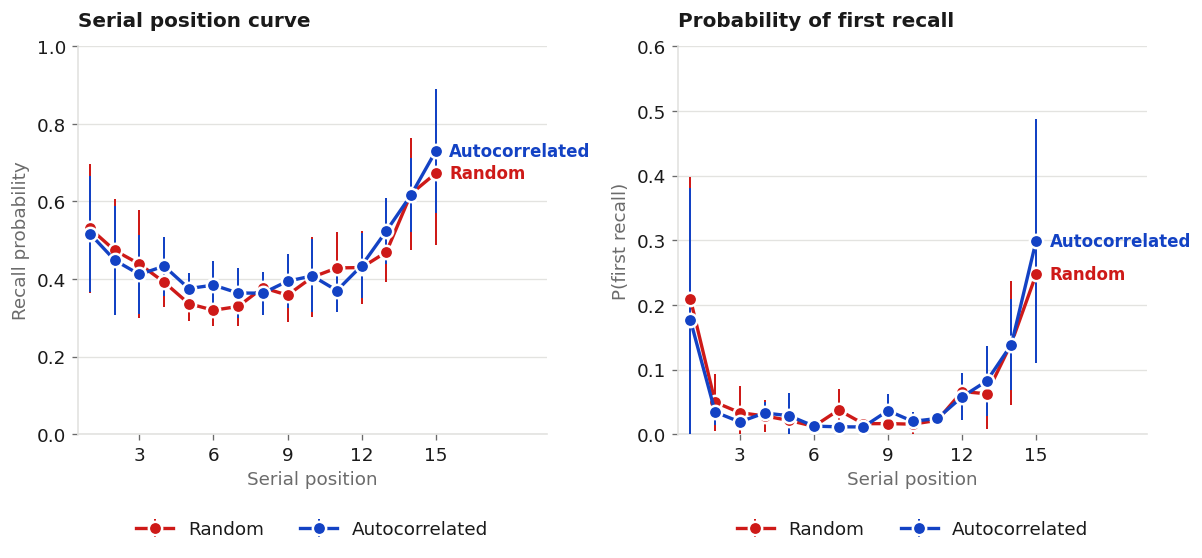

In [10]:
with publication_style():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    plots.plot_curve_by_list_type(res, "spcs", "Recall probability",
                                  "Serial position curve", ax=axes[0])
    plots.plot_curve_by_list_type(res, "pfrs", "P(first recall)",
                                  "Probability of first recall", ylim=(0, 0.6), ax=axes[1])
    fig.subplots_adjust(wspace=0.28)
    plt.show()

The lag-CRP shows the standard contiguity effect: recall jumps to nearby serial
positions, and forward transitions beat backward ones. Lag 0 is undefined, so the line is
broken there rather than interpolated across it.

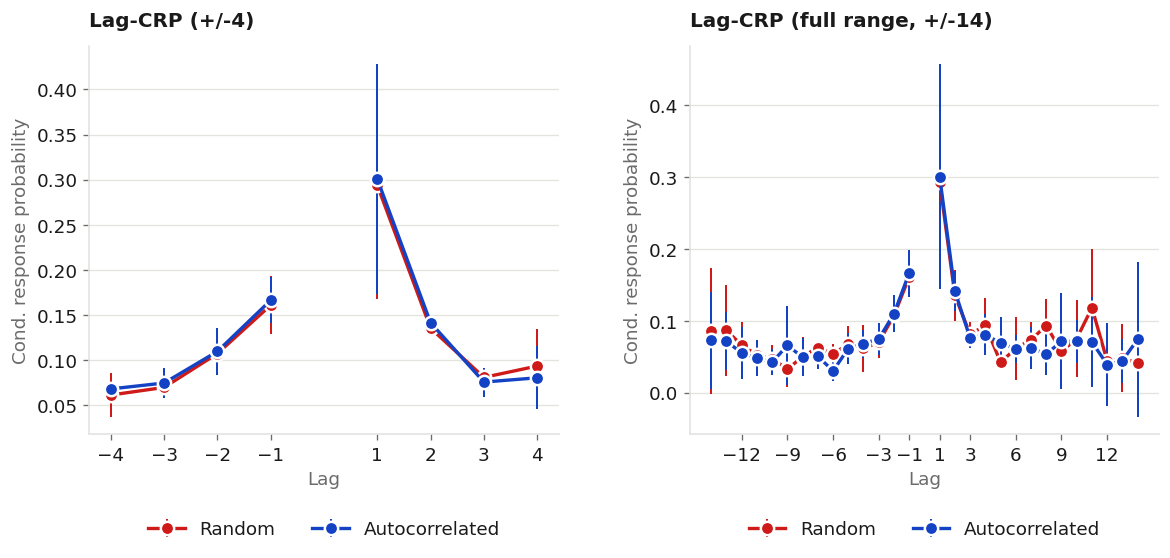

In [11]:
with publication_style():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    plots.plot_lag_crp(res, max_abs_lag=4, ax=axes[0])
    plots.plot_lag_crp(res, max_abs_lag=ll - 1, ax=axes[1])
    axes[1].set_title(f"Lag-CRP (full range, +/-{ll - 1})")
    fig.subplots_adjust(wspace=0.28)
    plt.show()

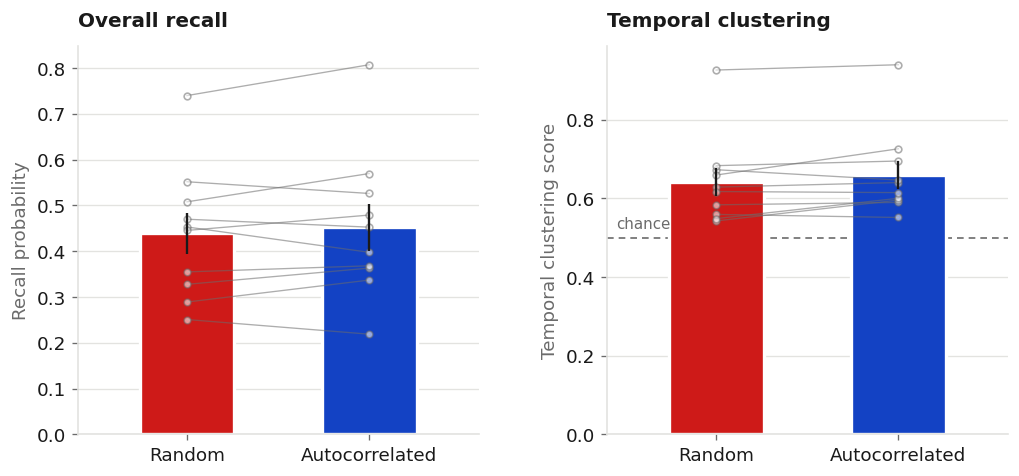

In [12]:
with publication_style():
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    plots.plot_paired_bars(
        (np.nanmean(res["rand"]["spcs"], axis=1), np.nanmean(res["temp"]["spcs"], axis=1)),
        "Recall probability", "Overall recall", ax=axes[0])
    plots.plot_paired_bars(
        (res["rand"]["temp_clusts"], res["temp"]["temp_clusts"]),
        "Temporal clustering score", "Temporal clustering", chance=0.5, ax=axes[1])
    fig.subplots_adjust(wspace=0.32)
    plt.show()

### Recall probability by item value

`prec_byval` is the SPC restricted to items of one value, averaged over serial positions.
It asks whether high-value words are remembered better — the premise the whole paradigm
rests on. With 50 values and 470 lists each value is thinly sampled, so the individual
points are noisy and the running mean is the thing to read.

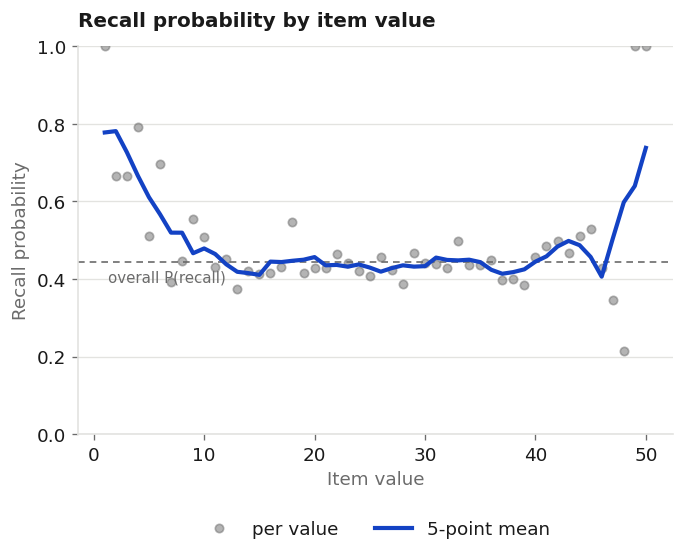

correlation between value and P(recall): r = -0.138


value range,1-10,11-20,21-30,31-40,41-50
P(recall),0.623,0.433,0.434,0.433,0.548


In [13]:
with publication_style():
    plots.plot_prec_byval(res)
    plt.show()

pv = np.nanmean(res["both"]["prec_byval"], axis=0)
deciles = pd.DataFrame(
    {"value range": [f"{lo + 1}-{lo + 10}" for lo in range(0, 50, 10)],
     "P(recall)": [np.nanmean(pv[lo:lo + 10]) for lo in range(0, 50, 10)]}
).set_index("value range")
print(f"correlation between value and P(recall): r = "
      f"{np.corrcoef(np.arange(1, 51), pv)[0, 1]:+.3f}")
deciles.round(3).T

## 5. Value estimation

The measures that motivate the experiment. For each list there is the subject's estimate
(`est_list`), the mean value of the items they recalled (`act_rec_list`), the mean value of
the items they did **not** (`act_nonrec_list`), and the mean value of everything studied
(`act_pres_list`) — the objectively correct answer.

These are not independent. The recalled and non-recalled values, each weighted by the share
of the list they cover, sum exactly to the whole-list value:

```
(nrec/ll) * ValueRecalled  +  ((ll-nrec)/ll) * ValueNotRecalled  ==  ValueAll
```

That identity is what makes section 9's two rounds comparable, and it is asserted below
rather than assumed.

In [14]:
c = res_fixed["both"]
nrec = c["act_nrec_list"]
partial = np.isfinite(nrec) & (nrec > 0) & (nrec < ll)

# The identity every model in sections 8-9 rests on.
lhs = (nrec[partial] * c["act_rec_list"][partial]
       + (ll - nrec[partial]) * c["act_nonrec_list"][partial]) / ll
assert np.allclose(lhs, c["act_pres_list"][partial], atol=1e-12)
print(f"decomposition holds exactly on all {int(partial.sum())} partially-recalled lists")

pd.DataFrame({
    "recalled items": c["act_rec_list"][partial],
    "non-recalled items": c["act_nonrec_list"][partial],
    "all studied items": c["act_pres_list"][partial],
    "subject's estimate": c["est_list"][partial],
}).describe().round(2)

decomposition holds exactly on all 462 partially-recalled lists


,recalled items,non-recalled items,all studied items,subject's estimate
count,462.00,462.00,462.00,462.00
mean,25.61,25.73,25.72,26.34
std,6.89,6.16,5.81,7.16
min,7.50,10.33,11.80,5.00
25%,20.67,21.40,21.15,22.00
50%,25.55,25.85,25.90,27.00
75%,30.62,29.98,29.87,32.00
max,42.25,47.00,39.20,46.00


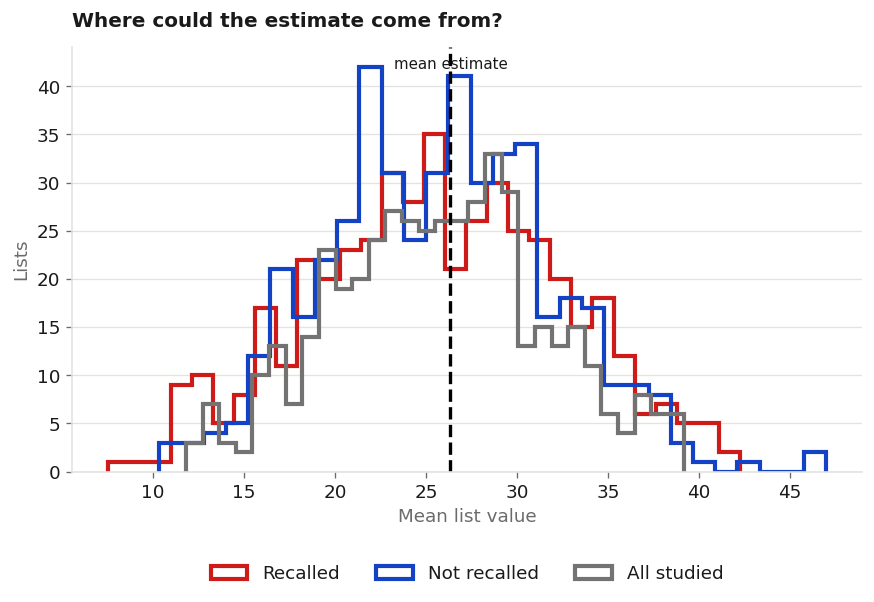

In [15]:
with publication_style():
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    for label, values, color in [
        ("Recalled", c["act_rec_list"][partial], RAND),
        ("Not recalled", c["act_nonrec_list"][partial], TEMP),
        ("All studied", c["act_pres_list"][partial], "0.45"),
    ]:
        ax.hist(values, bins=30, histtype="step", linewidth=2.5, label=label, color=color)
    ax.axvline(c["est_list"][partial].mean(), color="k", linestyle="--", linewidth=2)
    ax.annotate("mean estimate", (c["est_list"][partial].mean(), ax.get_ylim()[1]),
                fontsize=9, ha="center", va="top", xytext=(0, -6),
                textcoords="offset points")
    plots.style_axes(ax, ylabel="Lists", xlabel="Mean list value",
                     title="Where could the estimate come from?")
    ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.18))
    plt.show()

In [16]:
by_subject = pd.DataFrame({
    "|error| vs studied": c["abserr_pres_sub"],
    "|error| vs recalled": c["abserr_rec_sub"],
    "mean per-item |error|": c["abserr_rec_item_sub"],
    "guess-the-midpoint baseline": np.nanmean(c["baseerr_rec_list"], axis=1),
    "P(recall)": np.nanmean(c["spcs"], axis=1),
}, index=pd.Index(res["unilist"].astype(int), name="subject"))

beat = (by_subject["|error| vs studied"] < by_subject["guess-the-midpoint baseline"]).sum()
print(f"{beat} of {len(by_subject)} subjects beat the guess-the-midpoint baseline")
by_subject.round(3)

7 of 10 subjects beat the guess-the-midpoint baseline


,|error| vs studied,|error| vs recalled,mean per-item |error|,guess-the-midpoint baseline,P(recall)
subject,,,,,
657,2.236,3.184,3.158,4.403,0.235
658,2.140,3.276,3.120,4.937,0.347
660,6.711,7.101,2.533,4.584,0.424
661,7.099,7.100,2.129,4.873,0.460
666,3.082,3.235,2.389,5.940,0.772
668,3.607,3.219,3.243,5.325,0.312
670,2.733,3.717,3.410,4.632,0.361
672,2.883,3.496,4.939,4.373,0.537
673,7.113,7.199,3.177,4.713,0.540


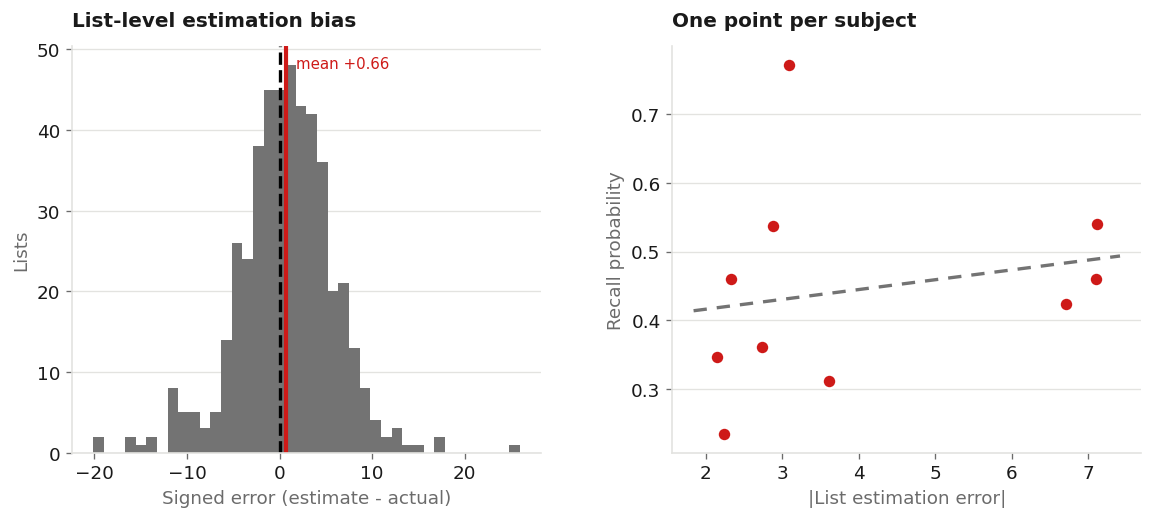

In [17]:
with publication_style():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

    # Signed error per list: is the estimate biased, and which way?
    signed = c["signerr_pres_list"][np.isfinite(c["signerr_pres_list"])]
    axes[0].hist(signed, bins=40, color="0.45")
    axes[0].axvline(0, color="k", linestyle="--", linewidth=2)
    axes[0].axvline(signed.mean(), color=RAND, linewidth=2.5)
    axes[0].annotate(f"mean {signed.mean():+.2f}", (signed.mean(), axes[0].get_ylim()[1]),
                     color=RAND, fontsize=9, ha="left", va="top",
                     xytext=(6, -6), textcoords="offset points")
    plots.style_axes(axes[0], ylabel="Lists", xlabel="Signed error (estimate - actual)",
                     title="List-level estimation bias")

    # Does estimating the list well go with remembering it well?
    xs = by_subject["|error| vs studied"].to_numpy()
    ys = by_subject["P(recall)"].to_numpy()
    slope, intercept = np.polyfit(xs, ys, 1)
    fit_x = np.array([xs.min() - 0.3, xs.max() + 0.3])
    axes[1].plot(fit_x, slope * fit_x + intercept, color="0.45", lw=2, ls=(0, (4, 3)))
    axes[1].scatter(xs, ys, s=70, color=RAND, zorder=3, edgecolor="white", linewidth=1.5)
    plots.style_axes(axes[1], ylabel="Recall probability", xlabel="|List estimation error|",
                     title="One point per subject")

    fig.subplots_adjust(wspace=0.28)
    plt.show()

Estimation error by session ordinal — do subjects get better with practice? Columns are
**ordinals, not session numbers**: a subject missing session 3 has their session-4 mean land
in column 3. The average within a session is a plain mean, so one undefined list makes the
whole session NaN.

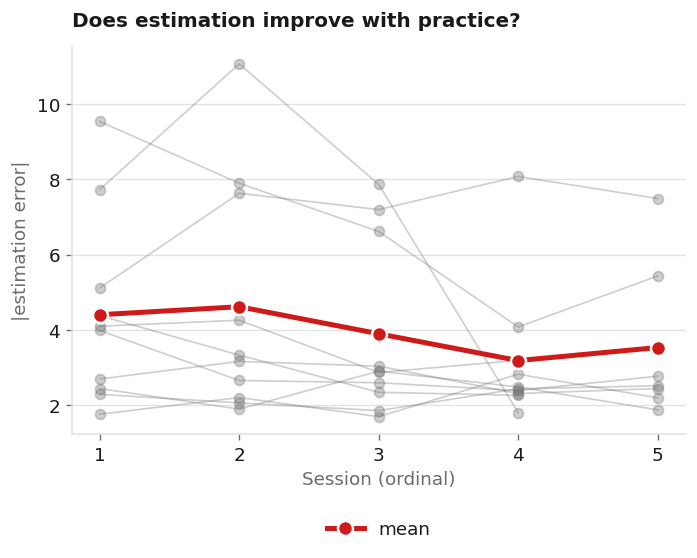

In [18]:
sess = res["both"]["abserr_pres_sess"]
with publication_style():
    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    x = np.arange(1, sess.shape[1] + 1)
    ax.plot(x, sess.T, "o-", alpha=0.35, linewidth=1, color="0.45")
    ax.plot(x, np.nanmean(sess, axis=0), "-o", linewidth=3, markersize=9,
            color=RAND, mec="white", mew=1.5, label="mean", zorder=4)
    plots.style_axes(ax, ylabel="|estimation error|", xlabel="Session (ordinal)",
                     title="Does estimation improve with practice?")
    ax.set_xticks(x)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18))
    plt.show()

## 6. Statistics

`stats_vaviv2.m`, minus its figure code, followed by the fuller contrast report ported from
vcbeh.

The MATLAB original used paired *t*-tests. Whether that is appropriate depends on the
sample, so the report below carries a Wilcoxon signed-rank result and a Shapiro–Wilk check
on the paired differences alongside each one. **On this data the `|value estimation error|`
differences are decisively non-normal (Shapiro *p* = 0.002)**, so the *t*-test's assumption
fails for that contrast and the Wilcoxon result is the one to read. The other two are fine
either way.

With n = 10 all of these have little power; the point of running them is parity and
auditability, not inference.

In [19]:
run_stats(res)

P(recall): M=0.44,SD=0.15 
Pres value error: M=3.99,SD=2.10 
Item rec value error: M=3.04,SD=0.80 
both: corr b/t abs_err LIST and p(recall), r=0.1997, p=0.5801 
both: corr b/t abs_err LIST and avg abs error for recalled items, r=-0.3292, p=0.3530 
abs err: rand>temp, p=0.7428, CI=[-0.361,0.489] 
p(recall): rand>temp, p=0.3664, CI=[-0.044,0.018] 
temp clusts: rand>temp, p=0.0929, CI=[-0.039,0.004] 


{'prec_sub': array([0.23466667, 0.34666667, 0.424     , 0.46      , 0.77166667,
        0.31166667, 0.36133333, 0.53733333, 0.54      , 0.46      ]),
 'prec': (0.44473333333333337, 0.15049521546063585),
 'abserr_pres': (3.9926999999999992, 2.104834590433751),
 'abserr_rec_item': (3.043429344719906, 0.8048931814214809),
 'corr_listerr_precall': (0.1997109197546414, 0.5801435753861766),
 'corr_listerr_itemerr': (-0.32919356811183265, 0.3529831990184007),
 'ttest_abserr': (0.742754068989933, -0.3614116415237266, 0.4886018411480987),
 'ttest_precall': (0.36635162948937194,
  -0.04361410961587284,
  0.017793493212190127),
 'ttest_tempclust': (0.09291469615066084,
  -0.039114510486971746,
  0.003616266156490848)}

In [20]:
print(format_report(res))

== Random vs autocorrelated lists (Wilcoxon signed-rank) ==
  |value estimation error|   median diff=+0.3291  W=   20.0  p=0.4922  n=10  [differences non-normal]
                             (paired t: mean diff=+0.0636, t(9)=+0.338, p=0.7428; Shapiro p=0.0023)
  recall probability         median diff=-0.0234  W=   17.0  p=0.3223  n=10
                             (paired t: mean diff=-0.0129, t(9)=-0.951, p=0.3664; Shapiro p=0.4627)
  temporal clustering        median diff=-0.0117  W=   11.0  p=0.1055  n=10
                             (paired t: mean diff=-0.0177, t(9)=-1.879, p=0.0929; Shapiro p=0.3541)

== Descriptives, all lists ==
  |value estimation error|   M=  3.993  SD= 2.105  n=10
  recall probability         M=  0.445  SD= 0.150  n=10
  temporal clustering        M=  0.650  SD= 0.110  n=10
  signed value error         M=  0.459  SD= 3.565  n=10
  |per-item value error|     M=  3.043  SD= 0.805  n=10

== |value error| vs recall probability ==
  r=+0.1997  p=0.5801  n=10  (fi

## 7. The published mixed model

`linreg_estval_presrecallval.m`:

$$\text{ValueEst} \sim 1 + \text{ValueRecall} \times \text{ValuePres} + (1 \mid \text{Subject})$$

Fitted with ML rather than REML, and *p*-values computed as two-sided *t* against residual
degrees of freedom, both to match MATLAB's `fitlme` defaults.

This model uses only `act_rec_list` and `act_pres_list`, so it is unaffected by the
weighting bugs and is fit on the MATLAB-faithful `res`.

In [21]:
table, fitted, coefs = run_regression(res, latex_path=ROOT / "linreg_estval.tex")

n observations: 469 (of 470 rows)


formula: ValueEst ~ ValueRecall * ValuePres + (1 | Subject)   [ML]

                 Name  Estimate     SE  tStat  DF     pValue
            Intercept    5.7364 2.8696 1.9990 465 4.6187e-02
          ValueRecall    0.1616 0.1199 1.3475 465 1.7849e-01
            ValuePres    0.6279 0.1307 4.8038 465 2.1035e-06
ValueRecall:ValuePres    0.0002 0.0041 0.0542 465 9.5676e-01

random intercept variance: 11.3278
residual variance:         16.3891

wrote /Users/zrentala/Documents/Value Courier/vcbehforzach/vcfrop/linreg_estval.tex


In [22]:
# The one dropped row is the single list with no correct recalls at all,
# which therefore has no ValueRecall.
print(f"rows built: {len(table)}   rows fitted: {int(fitted.nobs)}")
table.head()

rows built: 470   rows fitted: 469


,Subject,ValueEst,ValueRecall,ValuePres,WeValueRecall,AsValueRecall,ListType
0,1.0,28.0,27.4286,26.9333,27.0357,27.7500,rand
1,1.0,33.0,34.2500,29.1333,35.1875,33.2326,rand
2,1.0,22.0,21.5000,23.2000,23.4000,22.7000,rand
3,1.0,24.0,26.3333,28.1333,25.9630,27.9231,rand
4,1.0,32.0,33.0000,31.0667,31.8571,33.3636,rand


---

## 8. Recalled vs non-recalled: where does the estimate come from?

The question the decomposition exists to answer. With `nrec` of `ll` items recalled, a full
account predicts

```
ValueEst ~ (nrec/ll) * ValueRecalled + ((ll-nrec)/ll) * ValueNotRecalled
```

If the estimate were built only from what was recalled, the non-recalled coefficient would
be zero.

`nrec` differs list by list, so the original MATLAB fits **one model per recall count**.
vcbeh sweeps `nrec` 7–13. That range does not transfer: on 470 lists those cells hold as few
as one list. The range is therefore derived from the data — cells with at least 30 lists —
and the sizes are printed first so the choice is auditable.

**These models use `res_fixed`.** They depend on `act_nrec_list`, which the row-misalignment
bug corrupts for `rand` and `temp`; `vcfrop.linreg` refuses to build the table otherwise.

In [23]:
sizes = L.recall_count_sizes(res_fixed, ll)
viable = L.viable_recall_counts(res_fixed, ll)
print(f"cells with >= {L.MIN_LISTS_PER_SWEEP_CELL} lists: nrec {viable}")
print(f"vcbeh's hardcoded range was nrec 7-13, which here would hold "
      f"{', '.join(str(int(n)) for n in sizes.set_index('nrec').loc[7:13, 'n_lists'])} lists")
sizes.set_index("nrec").T

cells with >= 30 lists: nrec [3, 4, 5, 6, 7, 8, 9]
vcbeh's hardcoded range was nrec 7-13, which here would hold 63, 56, 35, 25, 13, 7, 8 lists


nrec,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
n_lists,0,4,28,35,56,59,63,63,56,35,25,13,7,8,10,0
n_subjects,0,3,8,8,7,9,9,10,10,8,7,5,3,3,1,0
viable,False,False,False,True,True,True,True,True,True,True,False,False,False,False,False,False


In [24]:
# The guard that stops these models being fit on misaligned recall counts.
try:
    L.build_list_table(res, ll, partial_only=True)
except L.InconsistentRecallCountError as exc:
    print("refused on the MATLAB-faithful result, as it should be:")
    print(f"  {exc}")

refused on the MATLAB-faithful result, as it should be:
  223 of 462 lists fail ValueRecallW + ValueNotRecallW == ValuePres (largest residual 12.2). Re-run the analysis with fix_op_weights=True.


In [25]:
additive = L.recalled_vs_nonrecalled(res_fixed, ll)
additive.round(4)

,nrec,n_lists,n_subjects,R2,b_int,p_int,b_ValueRecall,p_ValueRecall,b_ValueNotRecall,p_ValueNotRecall
0,3,35,8,0.8735,7.8589,0.0157,2.7391,0.0000,0.1875,0.2715
1,4,56,7,0.8534,3.3574,0.1876,1.4695,0.0000,0.7623,0.0000
2,5,59,9,0.8274,4.5140,0.0958,0.9919,0.0001,0.7763,0.0001
3,6,63,9,0.7443,4.6709,0.0710,1.3241,0.0001,0.5118,0.0285
4,7,63,10,0.6622,5.6374,0.0745,1.1191,0.0016,0.5262,0.1092
5,8,56,10,0.7220,4.0073,0.1776,1.1116,0.0000,0.5598,0.0366
6,9,35,8,0.7308,8.0671,0.0275,1.1954,0.0006,-0.0675,0.8998


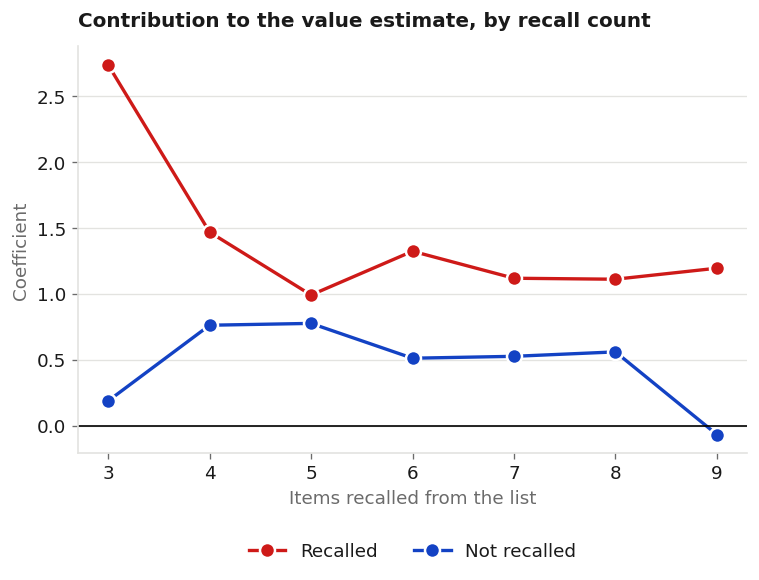

  nrec= 3  (35 lists, 8 subjects)  recalled=+2.739 (p=0.000)   non-recalled=+0.187 (p=0.271)
  nrec= 4  (56 lists, 7 subjects)  recalled=+1.469 (p=0.000)   non-recalled=+0.762 (p=0.000)
  nrec= 5  (59 lists, 9 subjects)  recalled=+0.992 (p=0.000)   non-recalled=+0.776 (p=0.000)
  nrec= 6  (63 lists, 9 subjects)  recalled=+1.324 (p=0.000)   non-recalled=+0.512 (p=0.029)
  nrec= 7  (63 lists, 10 subjects)  recalled=+1.119 (p=0.002)   non-recalled=+0.526 (p=0.109)
  nrec= 8  (56 lists, 10 subjects)  recalled=+1.112 (p=0.000)   non-recalled=+0.560 (p=0.037)
  nrec= 9  (35 lists, 8 subjects)  recalled=+1.195 (p=0.001)   non-recalled=-0.068 (p=0.900)


In [26]:
with publication_style():
    fig, ax = plt.subplots(figsize=(7.2, 4.4))
    for col, label, color in [("b_ValueRecall", "Recalled", RAND),
                              ("b_ValueNotRecall", "Not recalled", TEMP)]:
        ax.plot(additive["nrec"], additive[col], "-o", label=label, color=color,
                markersize=9, lw=2, mec="white", mew=1.5)
    ax.axhline(0, color="k", linewidth=1)
    plots.style_axes(ax, ylabel="Coefficient", xlabel="Items recalled from the list",
                     title="Contribution to the value estimate, by recall count")
    ax.set_xticks(additive["nrec"])
    ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.18))
    plt.show()

for _, row in additive.iterrows():
    print(f"  nrec={int(row['nrec']):2d}  ({int(row['n_lists'])} lists, "
          f"{int(row['n_subjects'])} subjects)  "
          f"recalled={row['b_ValueRecall']:+.3f} (p={row['p_ValueRecall']:.3f})   "
          f"non-recalled={row['b_ValueNotRecall']:+.3f} (p={row['p_ValueNotRecall']:.3f})")

### The `ValueAll x ValueRecalled` model, and why centring matters

A different model, and the one an earlier write-up of this analysis reported:

```
ValueEst ~ 1 + ValueAll * ValueRecalled + (1|Subject)
```

Two things separate it from the decomposition above:

- **`ValueRecalled` here is the raw mean value of the recalled items**, not the
  list-share-weighted term. They are on different scales and are not interchangeable.
- **The two predictors are collinear rather than complementary.** `ValueAll` already
  contains the recalled items, so the recalled term measures what it adds *beyond* the list
  as a whole — unlike the recalled/non-recalled split, whose two terms sum to `ValueAll`.

Because the two predictors **interact**, the coefficient on `ValueRecalled` is its effect
*where `ValueAll` is zero* — a list whose average value is nothing. Observed list averages
run from about 8 to 45, so that is an extrapolation well outside the data. Re-centring both
predictors at their means moves the reference to a typical list. It is the same fit —
identical R², identical interaction — read from a sensible reference point.

In [27]:
comparison = []
for centred in (False, True):
    fit = L.all_vs_recalled(res_fixed, center=centred).set_index("term")
    comparison.append({
        "predictors": "centred" if centred else "uncentred (as published)",
        "Value from ALL": f"{fit.loc['ValueAll', 'estimate']:.3f} "
                          f"(p={fit.loc['ValueAll', 'p']:.3g})",
        "Value from RECALLED": f"{fit.loc['ValueRecalled', 'estimate']:.3f} "
                               f"(p={fit.loc['ValueRecalled', 'p']:.3f})",
        "Interaction": f"{fit.loc['ValueAll:ValueRecalled', 'estimate']:+.4f} "
                       f"(p={fit.loc['ValueAll:ValueRecalled', 'p']:.3f})",
        "R2 (conditional)": f"{fit['R2'].iloc[0]:.3f}",
    })
pd.DataFrame(comparison).set_index("predictors")

,Value from ALL,Value from RECALLED,Interaction,R2 (conditional)
predictors,,,,
uncentred (as published),0.628 (p=2.1e-06),0.162 (p=0.178),+0.0002 (p=0.957),0.684
centred,0.633 (p=7.11e-16),0.167 (p=0.009),+0.0002 (p=0.957),0.684


In [28]:
print(L.format_all_vs_recalled(L.all_vs_recalled(res_fixed), "Pooled, uncentred"))
print()
print(L.format_all_vs_recalled(L.all_vs_recalled(res_fixed, by_condition=True),
                               "Split by list type"))

== Pooled, uncentred ==
  predictors uncentred: intercept is at a predictor value of 0
  All lists n=469 lists, 10 subjects, R2=0.684 conditional / 0.467 marginal
      Intercept                        +5.7364  t= +1.999  p=0.04619
      Value from ALL studied items     +0.6279  t= +4.804  p=2.103e-06
      Value from RECALLED items        +0.1616  t= +1.347  p=0.1785
      Interaction (All x Recalled)     +0.0002  t= +0.054  p=0.9568



== Split by list type ==
  predictors uncentred: intercept is at a predictor value of 0
  Random    n=237 lists, 10 subjects, R2=0.656 conditional / 0.424 marginal
      Intercept                        +7.1940  t= +1.757  p=0.08022
      Value from ALL studied items     +0.5866  t= +3.122  p=0.002021
      Value from RECALLED items        +0.1477  t= +0.861  p=0.3904
      Interaction (All x Recalled)     +0.0001  t= +0.022  p=0.9823
  Autocorr  n=232 lists, 10 subjects, R2=0.715 conditional / 0.511 marginal
      Intercept                        +4.4861  t= +1.160  p=0.2474
      Value from ALL studied items     +0.6694  t= +3.476  p=0.0006082
      Value from RECALLED items        +0.1533  t= +0.876  p=0.3819
      Interaction (All x Recalled)     +0.0009  t= +0.153  p=0.8783


**A note on R².** Two are reported: *marginal* (fixed effects only) and *conditional*
(including the subject random intercepts). The conditional one can never be the worse of the
two — adding the per-subject offsets cannot make predictions worse.

vcbeh computes both from `statsmodels`' `fittedvalues`, which in statsmodels 0.14.5 **already
contains the random effects**; adding the BLUPs to it double-counts them. On vcbeh's own data
that produces conditional 0.8311 < marginal 0.8366, which is impossible, and its two labels
are effectively swapped. This port derives both from the design matrix instead, so the
ordering holds by construction. Every coefficient, standard error, *t* and *p* still matches
vcbeh bit-for-bit; only the R² columns differ, and deliberately.

---

## 9. Bias by list type

Everything above pools random and autocorrelated lists, so a difference between them would
be invisible. This section fits **four mixed models** — one per list type, twice over.

**Round 1, uncorrected:** `ValueEst ~ ValuePres + (1|Subject)`

**Round 2, recall-corrected:** `ValueEst ~ ValueRecallW + ValueNotRecallW + (1|Subject)`,
each list weighted by **its own** recall count.

Because the two round-2 predictors sum exactly to the whole-list value, **round 1 is round 2
with the two sources forced to count equally**. Round 2 just lets the data say whether
recalled and non-recalled items carry the same weight.

In [29]:
uncorrected = L.condition_models(res_fixed, ll, corrected=False)
corrected = L.condition_models(res_fixed, ll, corrected=True)

print(L.format_condition_models(uncorrected, "ROUND 1 - estimate ~ actual list value"))
print()
print(L.format_condition_models(corrected, "ROUND 2 - recall-corrected"))

== ROUND 1 - estimate ~ actual list value ==
  predictors uncentred: intercept is at a predictor value of 0
  Random    n=237 lists, 10 subjects, R2=0.651
      Intercept                               +6.7944 [+3.5693, +10.0195]  t= +4.151  p=4.641e-05
      Value of ALL studied items              +0.7520 [+0.6589, +0.8452]  t=+15.907  p=3.68e-39
  Autocorr  n=233 lists, 10 subjects, R2=0.712
      Intercept                               +3.6841 [+0.5186, +6.8497]  t= +2.293  p=0.02275
      Value of ALL studied items              +0.8775 [+0.7854, +0.9697]  t=+18.756  p=2.562e-48

== ROUND 2 - recall-corrected ==
  predictors uncentred: intercept is at a predictor value of 0
  Random    n=235 lists, 10 subjects, R2=0.664
      Intercept                               +6.8603 [+3.6432, +10.0774]  t= +4.201  p=3.784e-05
      Value of RECALLED items                 +0.8486 [+0.7352, +0.9619]  t=+14.747  p=3.614e-35
      Value of NON-RECALLED items             +0.6723 [+0.5666, +0.7780] 

### Do the conditions actually differ?

Fitting the two separately shows what each looks like but cannot test whether they differ.
These pooled models carry a `ListType` interaction, and those terms are the test.

In [30]:
contrast_uncorrected = L.condition_contrast(res_fixed, ll, corrected=False)
contrast_corrected = L.condition_contrast(res_fixed, ll, corrected=True)

print(L.format_contrast(contrast_uncorrected, "ROUND 1 contrast"))
print()
print(L.format_contrast(contrast_corrected, "ROUND 2 contrast"))

== ROUND 1 contrast ==
  predictors uncentred: intercept is at a predictor value of 0
  n=470 lists, 10 subjects, R2=0.683   (the 'x list type' rows test the difference)
      Intercept                         +6.7446  t= +4.169  p=3.642e-05  *
      List type (Autocorr vs Random)    -2.9019  t= -1.695  p=0.0908
      Value of ALL studied items        +0.7541  t=+16.372  p=6.385e-48  *
      ALL studied  x  list type         +0.1163  t= +1.789  p=0.0743

== ROUND 2 contrast ==
  predictors uncentred: intercept is at a predictor value of 0
  n=462 lists, 10 subjects, R2=0.687   (the 'x list type' rows test the difference)
      Intercept                         +6.8052  t= +4.202  p=3.181e-05  *
      List type (Autocorr vs Random)    -3.2193  t= -1.865  p=0.06281
      Value of RECALLED items           +0.8392  t=+15.173  p=2.176e-42  *
      RECALLED  x  list type            +0.0815  t= +1.026  p=0.3053
      Value of NON-RECALLED items       +0.6839  t=+13.163  p=9.122e-34  *
      N

### Figures

The dashed diagonal is perfect accuracy. A fitted line crossing it — above at low list
values, below at high ones — is estimates compressing toward the middle of the range.

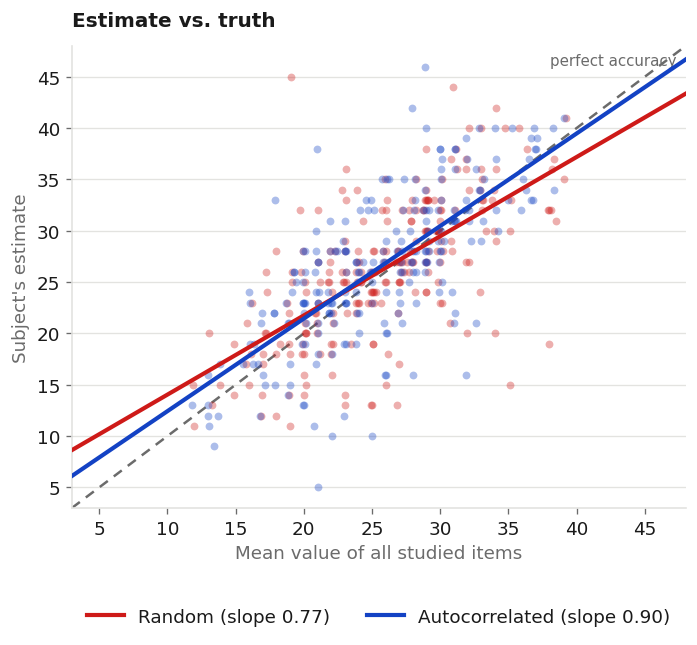

In [31]:
with publication_style():
    plots.plot_estimate_vs_actual(res_fixed, L.build_list_table, ll)
    plt.show()

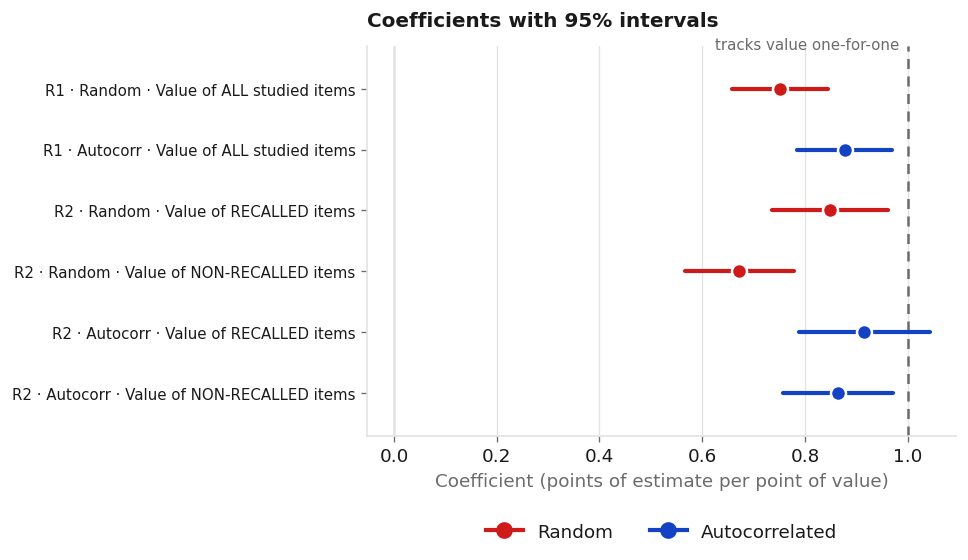

In [32]:
with publication_style():
    plots.plot_condition_coefficients(
        {"R1": uncorrected, "R2": corrected}
    )
    plt.tight_layout()
    plt.show()

### How to read a coefficient

A value is a number of points from 1 to 50, and so is the estimate, so each coefficient is
**points of estimate per point of actual value**. A coefficient of 0.87 means that when the
true value goes up by 1 point, the estimate goes up by only 0.87 — the estimate under-tracks.

Two things that are easy to misread:

- **The printed *p*-values test against zero**, which is not the interesting null. Nobody
  doubts the estimate tracks value; that is why they come out at 1e-30. The question is
  whether a coefficient differs from **1** (perfect tracking), and that is read off the
  confidence interval.
- **The intercept is not a bias estimate on its own.** It is the predicted estimate at a true
  value of zero, far outside the observed range. It only means something together with the
  slope.

In [33]:
full_table = pd.concat([
    uncorrected.assign(model="1. Uncorrected"),
    corrected.assign(model="2. Recall-corrected"),
], ignore_index=True)

full_table[[
    "model", "list_type", "label", "estimate", "se", "ci_low", "ci_high",
    "t", "p", "n_lists", "n_subjects", "R2",
]].rename(columns={"label": "coefficient", "list_type": "list type"}).style.format({
    "estimate": "{:+.4f}", "se": "{:.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}",
    "t": "{:+.2f}", "p": "{:.3g}", "R2": "{:.3f}",
}).hide(axis="index")

model,list type,coefficient,estimate,se,ci_low,ci_high,t,p,n_lists,n_subjects,R2
1. Uncorrected,Random,Intercept,+6.7944,1.6370,+3.5693,+10.0195,+4.15,4.64e-05,237,10,0.651
1. Uncorrected,Random,Value of ALL studied items,+0.7520,0.0473,+0.6589,+0.8452,+15.91,3.68e-39,237,10,0.651
1. Uncorrected,Autocorr,Intercept,+3.6841,1.6066,+0.5186,+6.8497,+2.29,0.0227,233,10,0.712
1. Uncorrected,Autocorr,Value of ALL studied items,+0.8775,0.0468,+0.7854,+0.9697,+18.76,2.56e-48,233,10,0.712
2. Recall-corrected,Random,Intercept,+6.8603,1.6328,+3.6432,+10.0774,+4.20,3.78e-05,235,10,0.664
2. Recall-corrected,Random,Value of RECALLED items,+0.8486,0.0575,+0.7352,+0.9619,+14.75,3.61e-35,235,10,0.664
2. Recall-corrected,Random,Value of NON-RECALLED items,+0.6723,0.0536,+0.5666,+0.7780,+12.53,7.34e-28,235,10,0.664
2. Recall-corrected,Autocorr,Intercept,+3.4329,1.6355,+0.2099,+6.6560,+2.10,0.0369,227,10,0.712
2. Recall-corrected,Autocorr,Value of RECALLED items,+0.9152,0.0647,+0.7876,+1.0428,+14.14,7.45e-33,227,10,0.712
2. Recall-corrected,Autocorr,Value of NON-RECALLED items,+0.8646,0.0545,+0.7571,+0.9720,+15.86,1.8e-38,227,10,0.712


In [34]:
contrasts = pd.concat([
    contrast_uncorrected.assign(model="1. Uncorrected"),
    contrast_corrected.assign(model="2. Recall-corrected"),
], ignore_index=True)

interactions = contrasts[contrasts["term"].str.contains("ListType")]
interactions[["model", "label", "estimate", "t", "p"]].rename(
    columns={"label": "coefficient"}
).round(4).style.hide(axis="index")

model,coefficient,estimate,t,p
1. Uncorrected,List type (Autocorr vs Random),-2.901900,-1.694700,0.090800
1. Uncorrected,ALL studied x list type,0.116300,1.788800,0.074300
2. Recall-corrected,List type (Autocorr vs Random),-3.219300,-1.865100,0.062800
2. Recall-corrected,RECALLED x list type,0.081500,1.026200,0.305300
2. Recall-corrected,NON-RECALLED x list type,0.162600,2.270500,0.023600


---

## 10. Value-estimation curves

**New analyses, not a port** — nothing equivalent exists in the MATLAB or in vcbeh.

At recall the subject values each item as they recall it, so every recalled item carries
both a true value and an estimate. That makes it possible to ask the questions the recall
curves ask, but about *estimation accuracy*:

| Recall measure | Value-estimation analog |
|---|---|
| SPC — P(recall) by serial position | estimation error by **serial position** |
| lag-CRP — P(transition) by lag | estimation error by **lag** |
| PFR — P(first recall) by serial position | estimation error by **output position**, OP 1 marked |

### How the values are normalised

Each list is z-scored on its own presented values, so lists are comparable:

```
mu, sd   = mean and sd of that list's 15 presented values
z_act(i) = (true value of recalled item i - mu) / sd
z_est(i) = (subject's estimate of it     - mu) / sd
signed   = z_est - z_act        # positive = overestimate
absolute = |z_est - z_act|
```

Centring on the list's own mean value puts every list on a common scale **without**
flattening the bias — a list-wide over- or under-estimate survives the transform, which is
the point. Per-list `sd` runs 4.9–10.1 here, so nothing degenerate.

### How they are aggregated

**Lists within a session, then sessions within a subject, then subjects** — unweighted at
each level. This is not the same as pooling every observation: a session in which more items
were recalled does not thereby count for more. Session columns are ordinals, matching the
rest of the pipeline.

Error bars are Loftus–Masson within-subject intervals, as elsewhere.

In [35]:
z = valuecurves.item_z_scores(data)
n_valid = int(z["valid"].sum())
from vcfrop.masks import make_clean_recalls_mask2d
n_recalls = int(make_clean_recalls_mask2d(data.recalls).sum())

print(f"clean recalls:            {n_recalls}")
print(f"of those, also estimated: {n_valid}  ({100 * n_valid / n_recalls:.1f}%)")
print()
print(f"grand mean signed z-error: {np.nanmean(z['signed'][z['valid']]):+.4f}")
print(f"grand mean |z-error|:      {np.nanmean(z['absolute'][z['valid']]):.4f}")

clean recalls:            3092


of those, also estimated: 2952  (95.5%)

grand mean signed z-error: -0.2875
grand mean |z-error|:      0.4273


### The SPC analog — estimation error by serial position

Two things are worth separating. `z_act` is the true value of the items that happened to be
recalled at each position — the sampling. `z_est` is what the subject said. The gap between
them is the error.

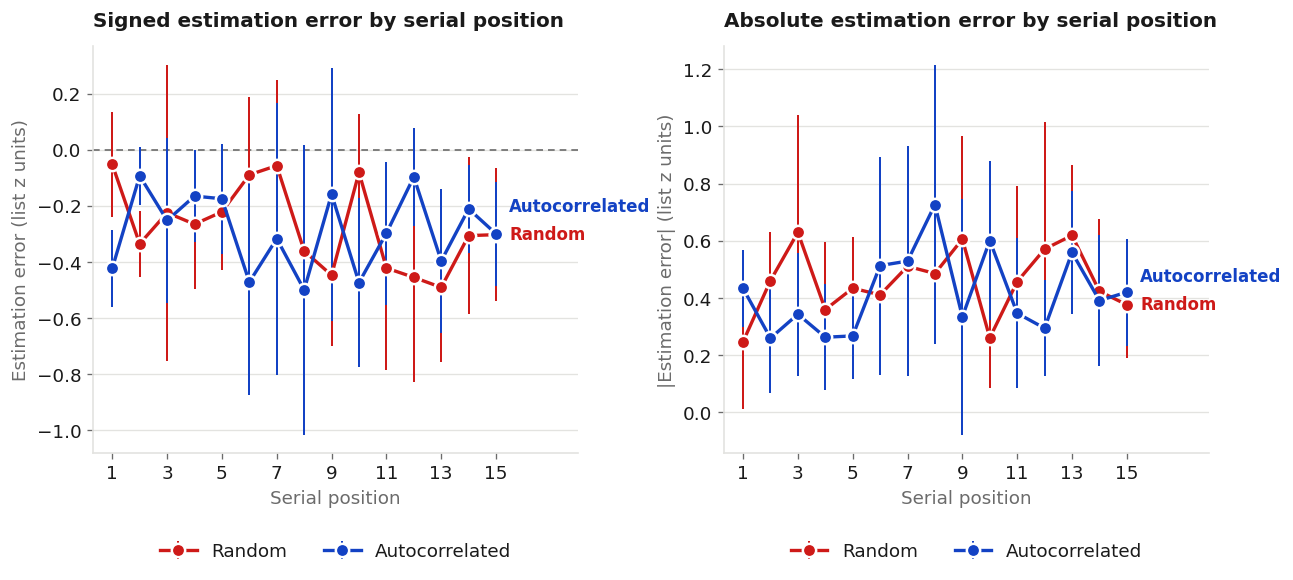

In [36]:
CONDS = {RAND_LABEL: data.pres_types.ravel() == 1,
         TEMP_LABEL: data.pres_types.ravel() == 2}
positions = np.arange(1, ll + 1)


def per_condition_counts(binning):
    """The smaller of the two conditions' bin counts.

    Each curve is drawn per condition, so pooled counts would overstate what
    either one rests on. Truncation and shading use this instead.
    """
    return np.minimum(*[
        valuecurves.observation_counts(data, sel, binning) for sel in CONDS.values()
    ])


sp_counts = per_condition_counts("serial_position")

with publication_style():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    plots.plot_value_curve(
        {k: valuecurves.error_by_serial_position(data, v, "signed") for k, v in CONDS.items()},
        positions, "Serial position", "Signed estimation error by serial position",
        counts=sp_counts, ax=axes[0])
    plots.plot_value_curve(
        {k: valuecurves.error_by_serial_position(data, v, "absolute") for k, v in CONDS.items()},
        positions, "Serial position", "Absolute estimation error by serial position",
        ylabel="|Estimation error| (list z units)", counts=sp_counts,
        zero_line=False, ax=axes[1])
    fig.subplots_adjust(wspace=0.3)
    plt.show()

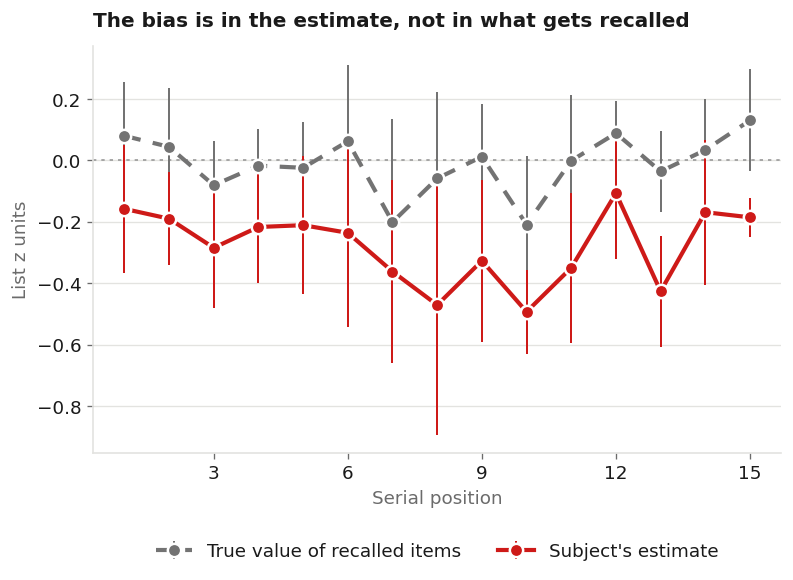

In [37]:
# Splitting the signed error into what was sampled and what was said.
with publication_style():
    fig, ax = plt.subplots(figsize=(7.4, 4.4))
    for measure, label, color, style in [
        ("z_act", "True value of recalled items", "0.45", (0, (4, 3))),
        ("z_est", "Subject's estimate", RAND, "-"),
    ]:
        curve = valuecurves.error_by_serial_position(data, None, measure)
        mean = np.nanmean(curve, axis=0)
        ax.errorbar(positions, mean, yerr=plots.loftus_masson(curve), color=color,
                    lw=2.5, ls=style, marker="o", ms=8, mfc=color, mec="white",
                    mew=1.5, elinewidth=1.2, capsize=0, label=label, zorder=3)
    ax.axhline(0, color="0.6", lw=1, ls=(0, (2, 3)), zorder=1)
    plots.style_axes(ax, ylabel="List z units", xlabel="Serial position",
                     title="The bias is in the estimate, not in what gets recalled")
    ax.set_xticks(range(3, ll + 1, 3))
    ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.18))
    plt.show()

### The PFR analog — estimation error by output position

Output position 1 is the literal PFR case and is marked. Later positions show how estimation
error evolves across the recall sequence.

**The curve is cut where the data run out.** A hierarchical mean makes a bin of three
observations look exactly like a bin of three hundred, and past about output position 13
only one subject contributes, so the Loftus–Masson interval collapses to nothing and the
line would imply a precision that is not there. The plot therefore stops at the last bin
with at least 20 observations; the full counts, including the tail that exists only because
intrusions push output positions past the list length, are tabulated below.

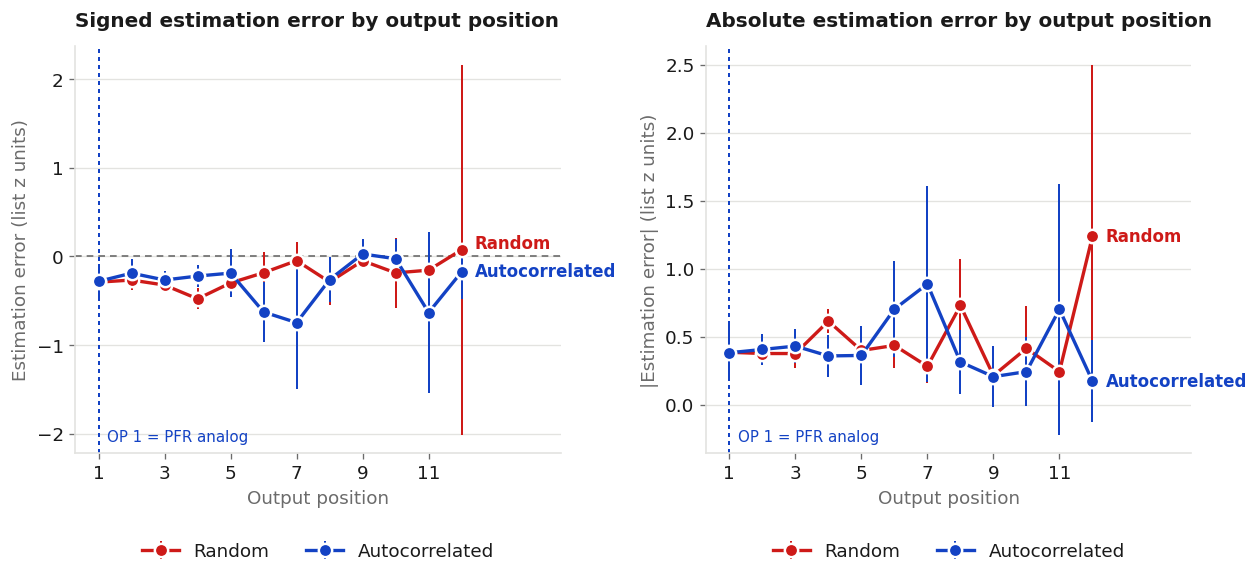

output position,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
observations (all lists),444,408,398,360,318,265,219,171,116,78,53,43,31,29,14,4,0,0,0,1
observations (smaller condition),220,203,196,172,159,130,109,82,58,38,26,21,15,13,5,1,0,0,0,0


In [38]:
op_counts = per_condition_counts("output_position")
n_op = len(op_counts)
op_x = np.arange(1, n_op + 1)

with publication_style():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    for ax, measure, title, ylab, zl in [
        (axes[0], "signed", "Signed estimation error by output position",
         "Estimation error (list z units)", True),
        (axes[1], "absolute", "Absolute estimation error by output position",
         "|Estimation error| (list z units)", False),
    ]:
        plots.plot_value_curve(
            {k: valuecurves.error_by_output_position(data, v, measure)
             for k, v in CONDS.items()},
            op_x, "Output position", title, ylabel=ylab,
            counts=op_counts, ax=ax, zero_line=zl)
        ax.axvline(1, color=TEMP, lw=1.2, ls=(0, (2, 2)), zorder=1)
        ax.annotate("OP 1 = PFR analog", (1, 0), xycoords=("data", "axes fraction"),
                    color=TEMP, fontsize=9, ha="left", va="bottom",
                    xytext=(5, 5), textcoords="offset points")
    fig.subplots_adjust(wspace=0.3)
    plt.show()

pd.DataFrame({
    "output position": op_x,
    "observations (all lists)": valuecurves.observation_counts(
        data, None, "output_position"),
    "observations (smaller condition)": op_counts,
}).set_index("output position").T

### The lag-CRP analog — estimation error by lag

Each *adjacent* pair of scored recalls contributes its lag, and the error scored is that of
the item transitioned **to**. Adjacency follows the same rule as the lag-CRP — an intrusion
or a repeat breaks the pair rather than being skipped over — so both measures are defined
over the same transitions. Lag 0 is undefined.

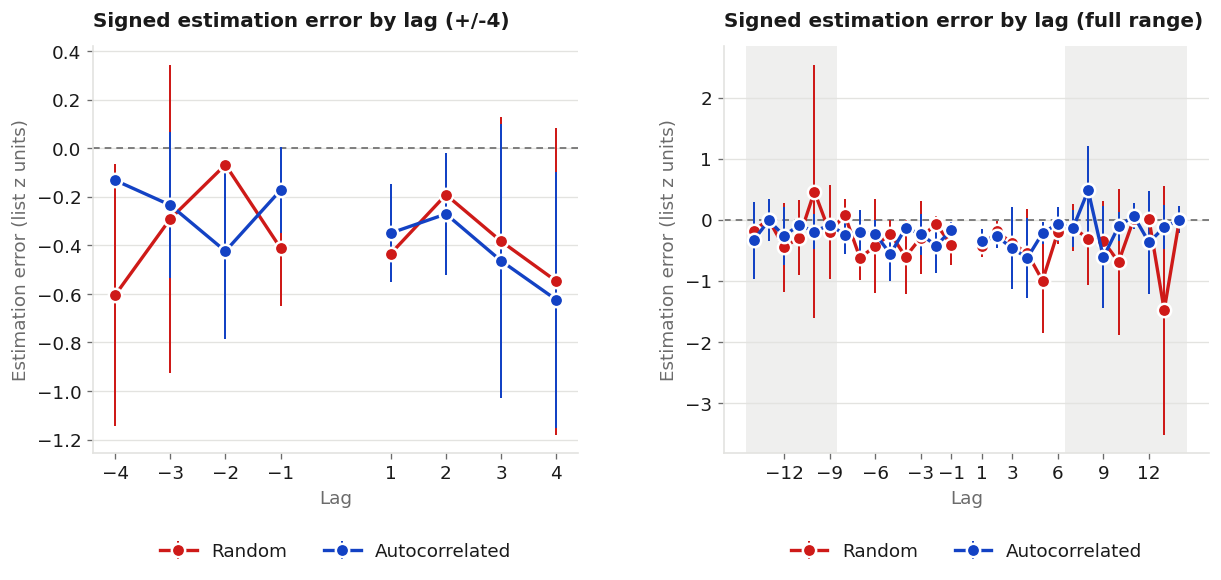

transitions per lag (lag 0 is undefined):
lag                -14  -13  -12  -11  -10  -9   -8   -7   -6   -5   -4   -3   -2   -1    0    1    2    3    4    5    6    7    8    9    10   11   12   13   14
all lists           19   27   28   30   35   36   47   58   48   75   78   99  139  245    0  633  210   95   83   50   46   41   36   35   31   24   14   13    6
smaller condition    9   13   13   14   15   16   23   29   20   37   36   49   69  121    0  309  103   47   40   20   23   17   14   17   15   12    5    6    3


In [39]:
lag_counts = per_condition_counts("lag")

with publication_style():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    plots.plot_value_curve_lag(
        {k: valuecurves.error_by_lag(data, v, "signed") for k, v in CONDS.items()},
        ll, counts=lag_counts, max_abs_lag=4,
        title="Signed estimation error by lag (+/-4)", ax=axes[0])
    plots.plot_value_curve_lag(
        {k: valuecurves.error_by_lag(data, v, "signed") for k, v in CONDS.items()},
        ll, counts=lag_counts, max_abs_lag=ll - 1,
        title=f"Signed estimation error by lag (full range)", ax=axes[1])
    fig.subplots_adjust(wspace=0.3)
    plt.show()

lags = np.arange(-(ll - 1), ll)
print("transitions per lag (lag 0 is undefined):")
print(pd.DataFrame({
    "all lists": valuecurves.observation_counts(data, None, "lag"),
    "smaller condition": lag_counts,
}, index=pd.Index(lags, name="lag")).T.to_string())

In [40]:
# Every curve, every measure, as one table of per-subject grand means.
summary = []
for binning, curves in valuecurves.value_curves(data).items():
    for measure, mat in curves.items():
        summary.append({
            "binning": binning, "measure": measure,
            "grand mean": float(np.nanmean(mat)),
            "across-subject sd": float(np.nanstd(np.nanmean(mat, axis=1), ddof=1)),
            "shape": str(mat.shape),
        })
pd.DataFrame(summary).set_index(["binning", "measure"]).round(4)

grand mean  across-subject sd     shape
binning         measure                                          
serial_position signed       -0.2670             0.0802  (10, 15)
                absolute      0.4298             0.1277  (10, 15)
                z_act        -0.0117             0.0529  (10, 15)
                z_est        -0.2787             0.0949  (10, 15)
output_position signed       -0.3049             0.1199  (10, 20)
                absolute      0.4846             0.1632  (10, 20)
                z_act         0.0443             0.0724  (10, 20)
                z_est        -0.2606             0.1212  (10, 20)
lag             signed       -0.2655             0.1097  (10, 29)
                absolute      0.4512             0.1840  (10, 29)
                z_act         0.0208             0.1109  (10, 29)
                z_est        -0.2447             0.1297  (10, 29)

---

## 11. Summary tables

The three models side by side, laid out like the original slide. All are fit on
`res_fixed` (10 participants, session 0 excluded), so they are directly comparable.

- **Table 1** — the original `ValueAll x ValueRecalled` model, split by list type.
- **Table 2** — the estimate from the list's true value alone, no recall information.
- **Table 3** — that split into recalled and non-recalled items, each weighted by how much
  of the list it covers. That weighting *is* the correction for how many items were recalled.

Recall-derived rows are in green.

In [41]:
SLIDE_LABELS = {
    "ValueAll": "Value from All", "ValuePres": "Value from All",
    "ValueRecalled": "Value from Recalled", "ValueRecallW": "Value from Recalled",
    "ValueNotRecallW": "Value from Non-Recalled",
    "ValueAll:ValueRecalled": "Interaction",
    "ValueRecallW:ValueNotRecallW": "Interaction", "Intercept": "Intercept",
}
SLIDE_ORDER = ["Value from All", "Value from Recalled", "Value from Non-Recalled",
               "Interaction", "Intercept"]
RECALL_ROWS = {"Value from Recalled", "Value from Non-Recalled"}


def slide_table(fit, caption):
    """One column pair per list type, rows ordered as on the slide."""
    named = fit.assign(row=fit["term"].map(SLIDE_LABELS))
    rows = [r for r in SLIDE_ORDER if r in set(named["row"])]
    conditions = list(dict.fromkeys(named["list_type"]))

    data_cols = {}
    for condition in conditions:
        block = named[named["list_type"] == condition].set_index("row")
        data_cols[(condition, "Estimate")] = (
            [f"{block.loc[r, 'estimate']:.3f}" for r in rows]
            + [f"{block['R2'].iloc[0]:.2f}"]
        )
        data_cols[(condition, "p")] = (
            ["< .001" if block.loc[r, "p"] < 0.001 else f"{block.loc[r, 'p']:.3f}"
             for r in rows] + ["--"]
        )

    table = pd.DataFrame(data_cols, index=rows + ["R2"])
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    counts = ", ".join(
        f"{c}: {int(named[named['list_type'] == c]['n_lists'].iloc[0])} lists"
        for c in conditions
    )
    return (
        table.style
        .set_caption(
            f"{caption}<br><span style='font-weight:400;font-size:90%;color:#555'>"
            f"10 participants &middot; {counts} &middot; one observation per list</span>")
        .set_table_styles([
            {"selector": "caption",
             "props": [("caption-side", "top"), ("text-align", "left"),
                       ("font-weight", "700"), ("font-size", "110%"),
                       ("padding-bottom", "10px"), ("line-height", "1.5")]},
            {"selector": "th",
             "props": [("text-align", "center"), ("font-weight", "700"),
                       ("padding", "5px 16px"), ("border-bottom", "1.5px solid #333")]},
            {"selector": "th.row_heading",
             "props": [("text-align", "left"), ("border-bottom", "none")]},
            {"selector": "td", "props": [("text-align", "center"), ("padding", "5px 16px")]},
            {"selector": "", "props": [("border-collapse", "collapse")]},
        ])
        .apply(lambda row: ["color:#1a7f37;font-weight:600" if row.name in RECALL_ROWS
                            else "" for _ in row], axis=1)
        .set_properties(subset=pd.IndexSlice[["R2"], :],
                        **{"border-top": "1.5px solid #333", "font-weight": "600"})
    )


display(slide_table(
    L.all_vs_recalled(res_fixed, by_condition=True),
    "Table 1 &middot; Original model, split by list type<br>"
    "<code>Estimate ~ 1 + ValueAll * ValueRecalled + (1|Subject)</code>"))

display(slide_table(
    L.condition_models(res_fixed, ll, corrected=False),
    "Table 2 &middot; Not corrected for the number of items recalled<br>"
    "<code>Estimate ~ ValueAll + (1|Subject)</code>"))

display(slide_table(
    L.condition_models(res_fixed, ll, corrected=True, interaction=True),
    "Table 3 &middot; Corrected for the number of items recalled<br>"
    "<code>Estimate ~ ValueRecalled * ValueNotRecalled + (1|Subject)</code>"))

---

## 12. The output-position weighting bugs

`ana_vavi_e2frop.m` builds output-position-weighted recall values, and two defects affect
them:

1. **Row misalignment** — the loop runs over the filtered row count but indexes the
   *unfiltered* `data.recalls`, so `max_op` is read from an unrelated trial. This is a
   **regression**: the sibling `../vcbeh/ana_vavi.m:136` already reads the filtered array.
   It also corrupts `act_nrec_list` for `rand`/`temp`, which is why sections 8–11 use
   `res_fixed` and why `vcfrop.linreg` refuses to build its tables otherwise.
2. **Ascending weights are not ascending** — `wtd_rec_mask_asc` is built from
   `wtd_rec_mask_dsc` one line after that array is overwritten, giving a symmetric bow
   rather than a ramp. Present in `../vcbeh/ana_vavi.m:138` too, so it is long-standing.

`fix_op_weights=True` corrects both. The pipeline reproduces MATLAB by default so section 3
stays meaningful.

In [42]:
rows = []
for condition in ("both", "rand", "temp"):
    for field in ("act_weightrec_list", "act_wtascrec_list", "act_nrec_list"):
        a, b = res[condition][field], res_fixed[condition][field]
        finite = ~np.isnan(a) & ~np.isnan(b)
        delta = np.abs(a[finite] - b[finite])
        rows.append({"condition": condition, "field": field,
                     "cells changed": f"{int((delta > 1e-9).sum())} / {finite.sum()}",
                     "max |diff|": delta.max()})
pd.DataFrame(rows).set_index(["condition", "field"]).round(3)

cells changed  max |diff|
condition field                                       
both      act_weightrec_list       0 / 469       0.000
          act_wtascrec_list      463 / 469       5.841
          act_nrec_list            0 / 469       0.000
rand      act_weightrec_list     215 / 237       4.000
          act_wtascrec_list      234 / 237       8.400
          act_nrec_list          117 / 237      13.200
temp      act_weightrec_list     208 / 232       2.600
          act_wtascrec_list      230 / 232      13.390
          act_nrec_list          114 / 232      13.600

The descending weights are untouched for `both` — with no rows filtered out, the
misaligned index happens to be the right one. The ascending weights move everywhere.

So does any **published** result change?

In [43]:
from vcfrop.regression import build_table as build_published, fit as fit_published

comparison = {}
for label, r in (("as published", res), ("fix_op_weights=True", res_fixed)):
    t = build_published(r)
    _, published = fit_published(t, "ValueEst ~ ValueRecall * ValuePres")
    _, weighted = fit_published(t, "ValueEst ~ WeValueRecall * ValuePres")
    comparison[(label, "published model")] = published.set_index("Name")["Estimate"]
    comparison[(label, "weighted variant")] = weighted.set_index("Name")["Estimate"]

pd.DataFrame(comparison).round(4)

as published                  fix_op_weights=True  \
                        published model weighted variant     published model   
Name                                                                           
Intercept                        5.7364           6.1975              5.7364   
ValuePres                        0.6279           0.6395              0.6279   
ValueRecall                      0.1616              NaN              0.1616   
ValueRecall:ValuePres            0.0002              NaN              0.0002   
WeValueRecall                       NaN           0.1124                 NaN   
WeValueRecall:ValuePres             NaN           0.0010                 NaN   

                                          
                        weighted variant  
Name                                      
Intercept                         6.2924  
ValuePres                         0.6428  
ValueRecall                          NaN  
ValueRecall:ValuePres                NaN  
WeValueRecall                     0.1006  
WeValueRecall:ValuePres           0.0011

**The published model does not change.** It uses `act_rec_list` and `act_pres_list`
only — never the weighted columns — so its coefficients are identical either way. The bugs
reach `act_weightrec_list`, `act_wtascrec_list` and `act_nrec_list`, which feed the
commented-out MATLAB alternatives and the decomposition models in sections 8–11. Those
models are fit on the corrected result throughout.

---

### Reproducing this

```
python -m pytest tests/                                                # 79 tests
python scripts/run_analysis.py data_083026_xs0.mat res_083026_xs0.mat  # 69/69 parity
python scripts/reverse_value_from_mask.py                              # how value_from_mask was recovered
python -m nbconvert --to notebook --execute --inplace notebooks/vcfrop_analysis.ipynb
```

The models in sections 8–11 were validated against `../vcbeh` by running both
implementations on vcbeh's own `data_050526_45sess.mat`: estimates, standard errors, *t* and
*p* agree to 0.00e+00 across every model and option.